# Exploratory Data Analysis: U.S. College Costs and Earnings

This notebook analyzes `institutions.csv`, which contains 3,392 U.S. colleges and 12 attributes. The data comes from the [College ROI Dataset](https://github.com/thomasthinks/college-roi-data), listed in the Education section of [Awesome Public Datasets](https://github.com/awesomedata/awesome-public-datasets#education).


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_style("whitegrid")
sns.set_context("notebook")

df = pd.read_csv("institutions.csv")

## 1. Dataset structure and quality

The first step is to inspect the rows, data types, summary statistics, and missing values.

In [39]:
print("Shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nColumn information:")
df.info()
print("\nMissing values:")
print(df.isna().sum())

df.describe(include="all").T

Shape: (3392, 12)

First five rows:
   unitid                    name          city state            control  \
0  214023     ASPIRA City College  Philadelphia    PA  private-nonprofit   
1  446127    ATA Career Education   Spring Hill    FL  private-forprofit   
2  447935             ATA College    Louisville    KY  private-forprofit   
3  449728             ATA College         Tulsa    OK  private-forprofit   
4  452373  ATA College-Cincinnati    Cincinnati    OH  private-forprofit   

       level  in_state_tuition  out_of_state_tuition  room_board  \
0   two-year             12147                 12147       10080   
1  four-year             14250                 14250        8635   
2   two-year             13790                 13790        8676   
3   two-year             15000                 15000       10110   
4  four-year             14250                 14250        8936   

   median_earnings_10_year  median_earnings_5_year  program_count  
0                      NaN    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unitid,3392.0,NaN,NaN,NaN,228716.375295,113515.530029,100654.0,155507.25,196299.0,231875.25,499662.0
name,3392,3360,Lincoln University,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,3392,1703,Brooklyn,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,3392,51,CA,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
control,3392,3,public,1568,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level,3392,2,four-year,2348,NaN,NaN,NaN,NaN,NaN,NaN,NaN
in_state_tuition,3392.0,NaN,NaN,NaN,18100.801887,16046.01172,0.0,6328.75,12270.0,25330.25,93980.0
out_of_state_tuition,3392.0,NaN,NaN,NaN,21457.029776,15036.811862,0.0,10001.5,16539.0,29694.5,93980.0
room_board,3392.0,NaN,NaN,NaN,12013.046875,4424.28641,675.0,8979.5,11662.0,14536.0,39100.0
median_earnings_10_year,1661.0,NaN,NaN,NaN,55803.301023,15442.726433,10466.0,47385.0,53915.0,62704.0,174491.0


In [40]:
df.head()

,unitid,name,city,state,control,level,in_state_tuition,out_of_state_tuition,room_board,median_earnings_10_year,median_earnings_5_year,program_count
0,214023,ASPIRA City College,Philadelphia,PA,private-nonprofit,two-year,12147,12147,10080,NaN,NaN,0
1,446127,ATA Career Education,Spring Hill,FL,private-forprofit,four-year,14250,14250,8635,NaN,NaN,0
2,447935,ATA College,Louisville,KY,private-forprofit,two-year,13790,13790,8676,NaN,NaN,0
3,449728,ATA College,Tulsa,OK,private-forprofit,two-year,15000,15000,10110,NaN,NaN,0
4,452373,ATA College-Cincinnati,Cincinnati,OH,private-forprofit,four-year,14250,14250,8936,NaN,NaN,0


### Initial findings

- The dataset has 3,392 rows and 12 columns.
- Six columns are numerical measurements: the two tuition columns, room and board, the two earnings columns, and program count.
- Five columns are categorical: name, city, state, control, and level.
- `median_earnings_10_year` and `median_earnings_5_year` each have 1,731 missing values. All other columns are complete. 

## 2. One-dimensional numerical distributions

Outliers are defined using the standard **1.5 × IQR rule**: values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

In [41]:
numerical_columns = [
    "in_state_tuition",
    "out_of_state_tuition",
    "room_board",
    "median_earnings_10_year",
    "median_earnings_5_year",
    "program_count",
]

numerical_summary = df[numerical_columns].agg(["min", "max", "mean", "median"]).T
outlier_counts = {}

for column in numerical_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_counts[column] = ((df[column] < lower_limit) | (df[column] > upper_limit)).sum()

numerical_summary["outlier_count"] = pd.Series(outlier_counts)
numerical_summary.round(2)

,min,max,mean,median,outlier_count
in_state_tuition,0.0,93980.0,18100.80,12270.0,171
out_of_state_tuition,0.0,93980.0,21457.03,16539.0,115
room_board,675.0,39100.0,12013.05,11662.0,50
median_earnings_10_year,10466.0,174491.0,55803.30,53915.0,85
median_earnings_5_year,8435.0,130436.0,41896.75,40276.0,85
program_count,0.0,108.0,8.66,0.0,294


### Numerical analysis

Every mean is greater than its corresponding median, indicating right-skewed distributions. Program count is especially right-skewed because at least half of the institutions have a value of zero while a smaller group has many programs.

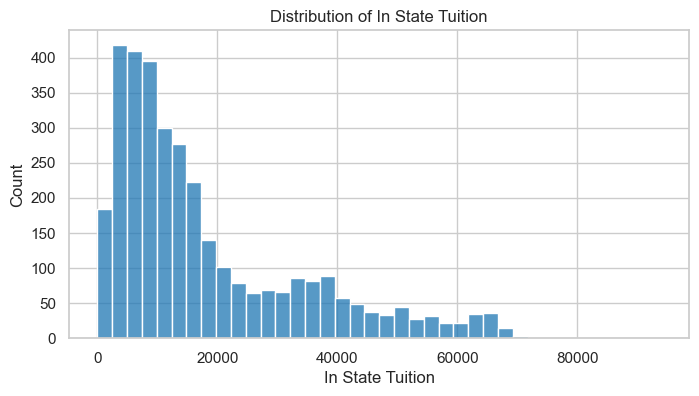

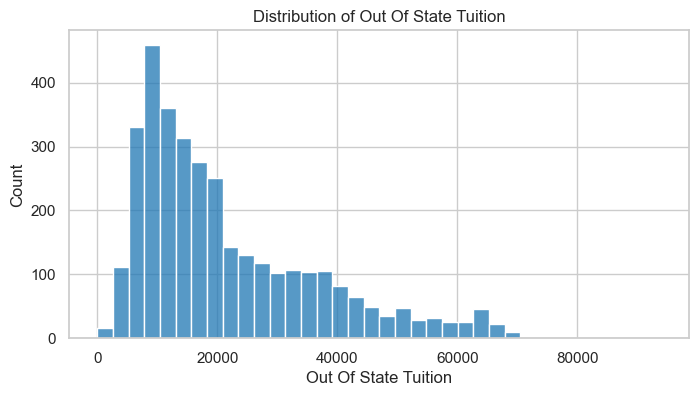

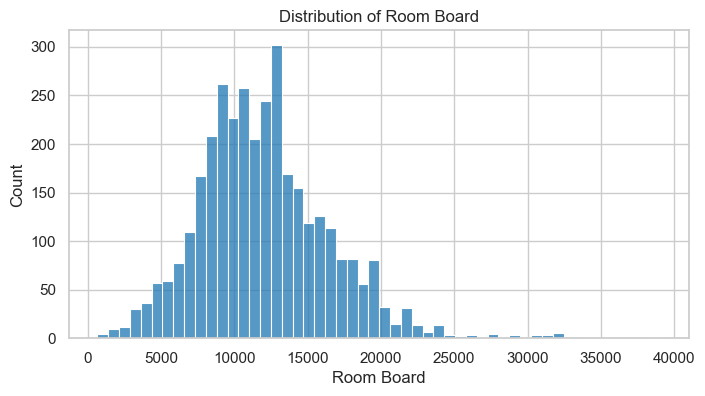

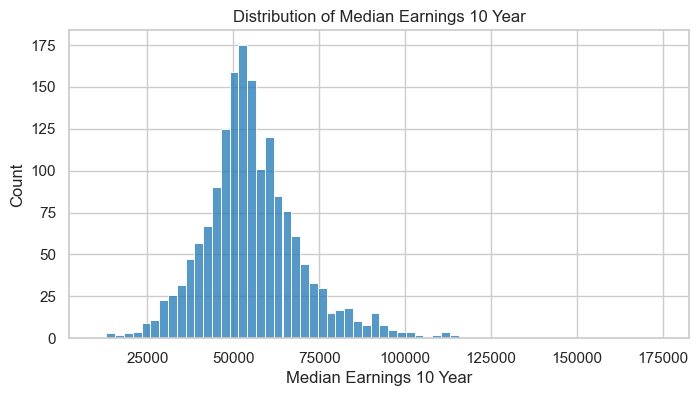

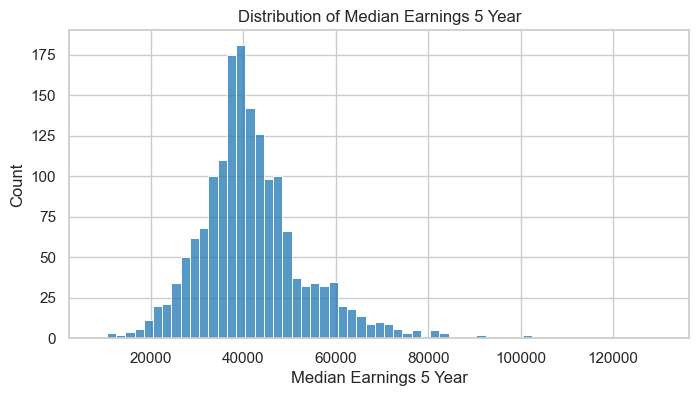

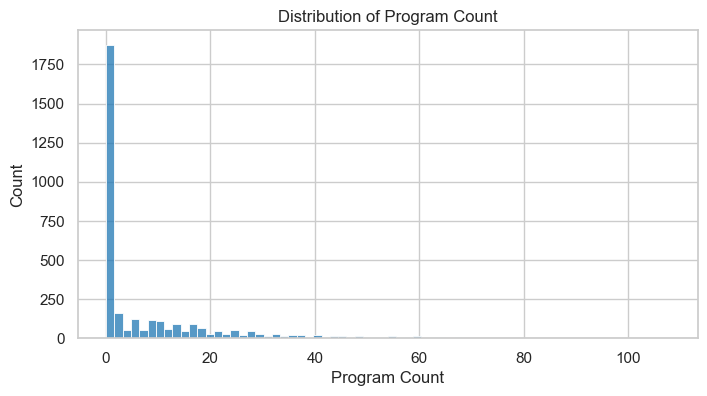

In [42]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    g = sns.histplot(data=df, x=column)
    g.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    g.set(xlabel=column.replace("_", " ").title(), ylabel="Count")
    plt.show()

## 3. One-dimensional categorical distributions

Bar charts show category counts. `name` and `city` have 3,360 and 1,703 unique values, respectively, so their charts show the 15 most frequent values to remain readable. The other categorical charts show every category.

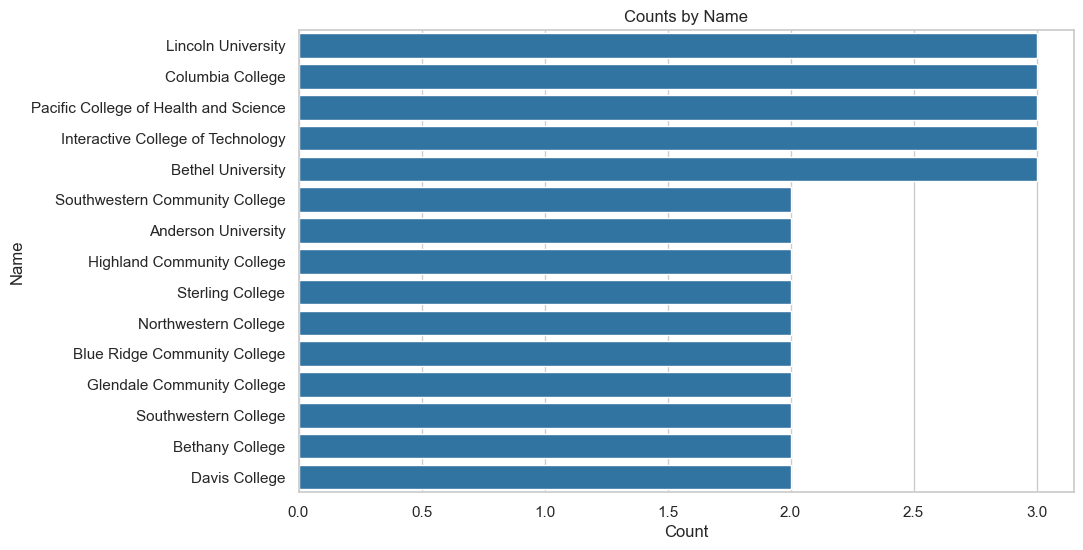

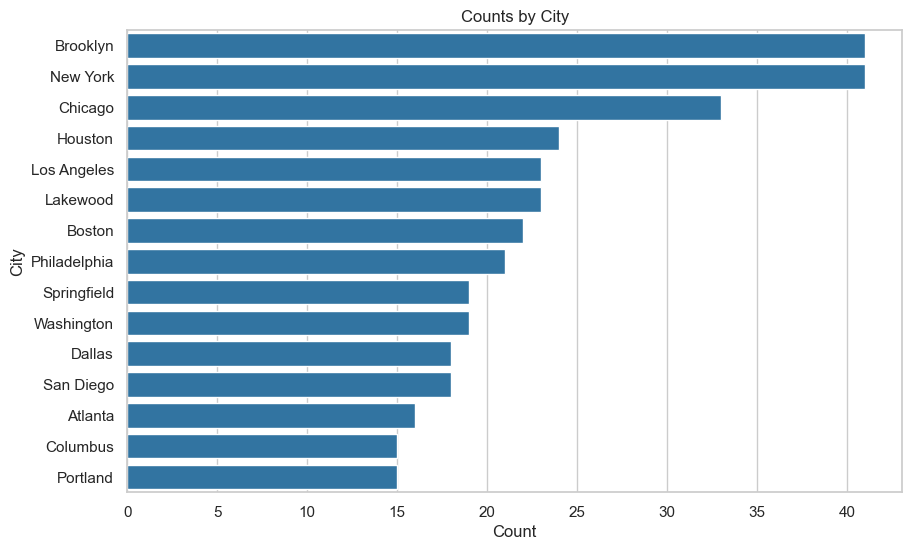

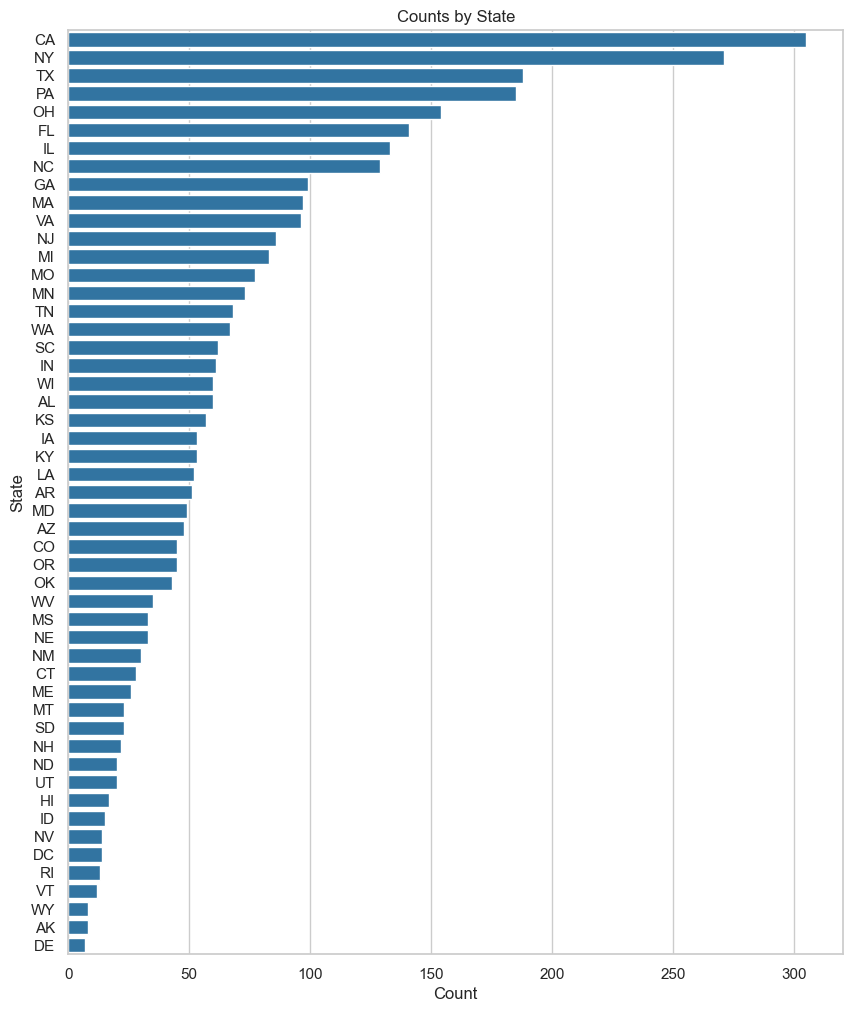

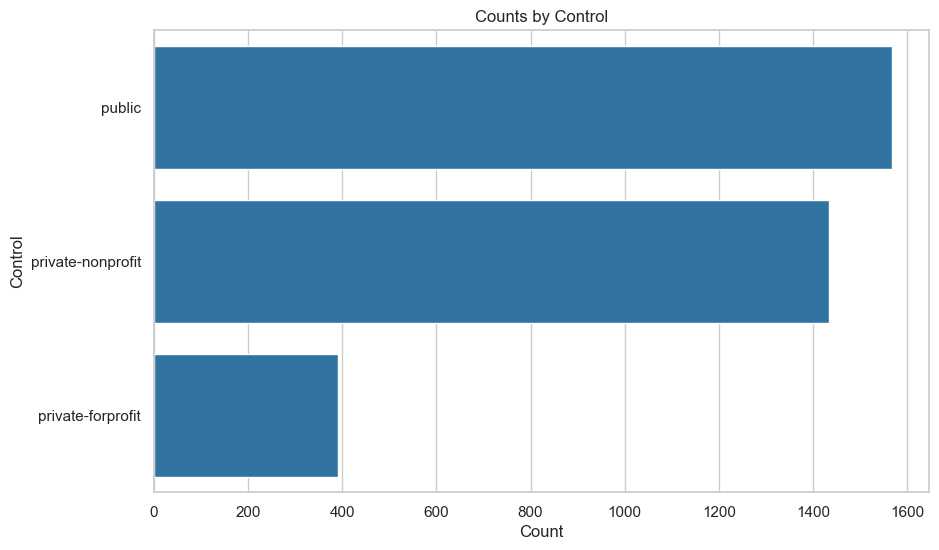

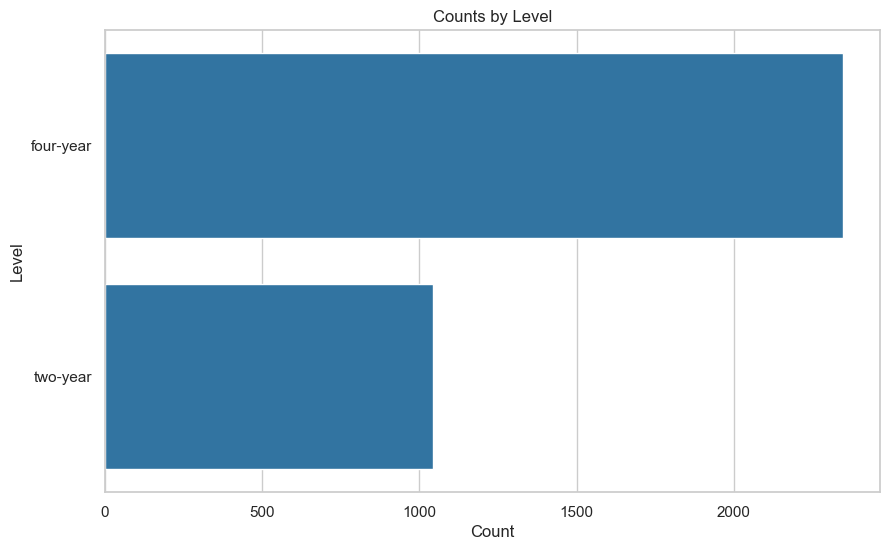

In [43]:
categorical_columns = ["name", "city", "state", "control", "level"]

for column in categorical_columns:
    counts = df[column].value_counts()
    order = counts.head(15).index if column in ["name", "city"] else counts.index
    height = 12 if column == "state" else 6
    plt.figure(figsize=(10, height))
    g = sns.countplot(data=df, y=column, order=order)
    g.set_title(f"Counts by {column.replace('_', ' ').title()}")
    g.set(xlabel="Count", ylabel=column.replace("_", " ").title())
    plt.show()

### Categorical summary

- No categorical column has missing values.
- Several college names occur three times, so names are not completely unique.
- Brooklyn and New York are tied as the most common cities with 41 institutions each.
- California is the most common state with 305 institutions.
- Public institutions are the largest control group with 1,568 records, followed by 1,433 private nonprofit and 391 private for-profit institutions.
- Four-year institutions are more common than two-year institutions: 2,348 compared with 1,044.

Numerical mean and median are not meaningful for labels, so frequencies are the appropriate summaries for these variables.

## 4. Side-by-side box plot

The box height represents the IQR, the line inside each box is the median, the whiskers extend to non-outlier values, and points beyond the whiskers are outliers.

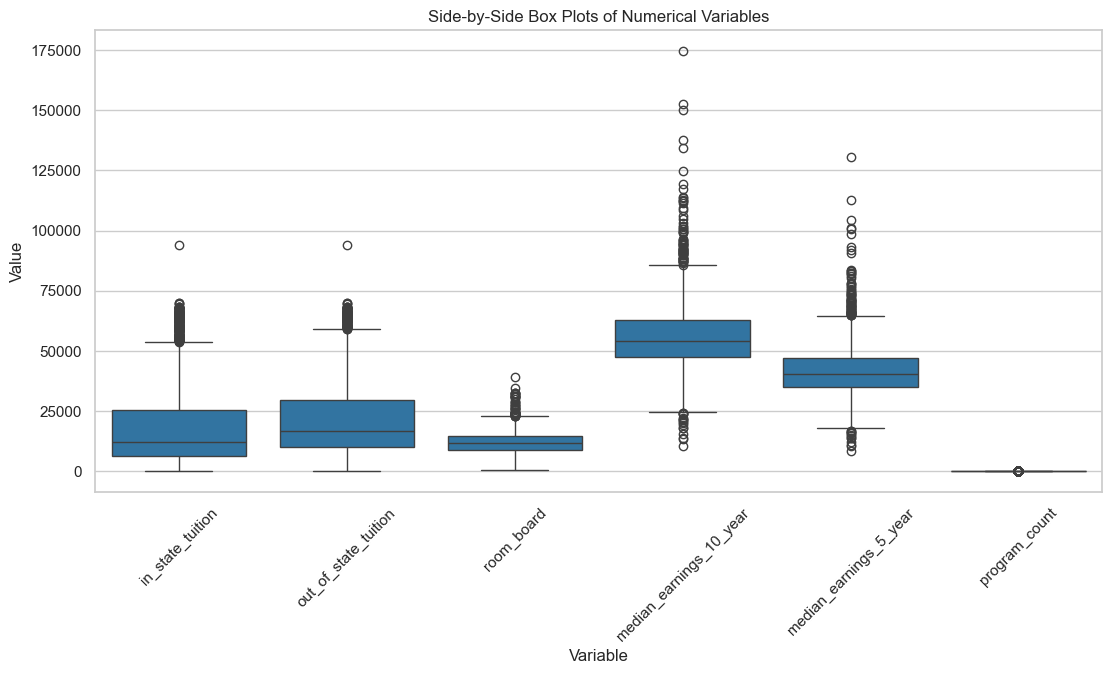

In [44]:
box_data = df[numerical_columns].melt(var_name="variable", value_name="value")

plt.figure(figsize=(13, 6))
g = sns.boxplot(data=box_data, x="variable", y="value")
g.set_title("Side-by-Side Box Plots of Numerical Variables")
g.set(xlabel="Variable", ylabel="Value")
plt.xticks(rotation=45)
plt.show()

The box plot confirms high-value outliers in every numerical measure. The tuition and earnings variables are on much larger scales than program count, but keeping them in one plot provides the requested side-by-side comparison.

## 5. Pairwise relationships between numerical variables

The scatter-plot matrix uses the 1,661 institutions with both earnings measurements available.

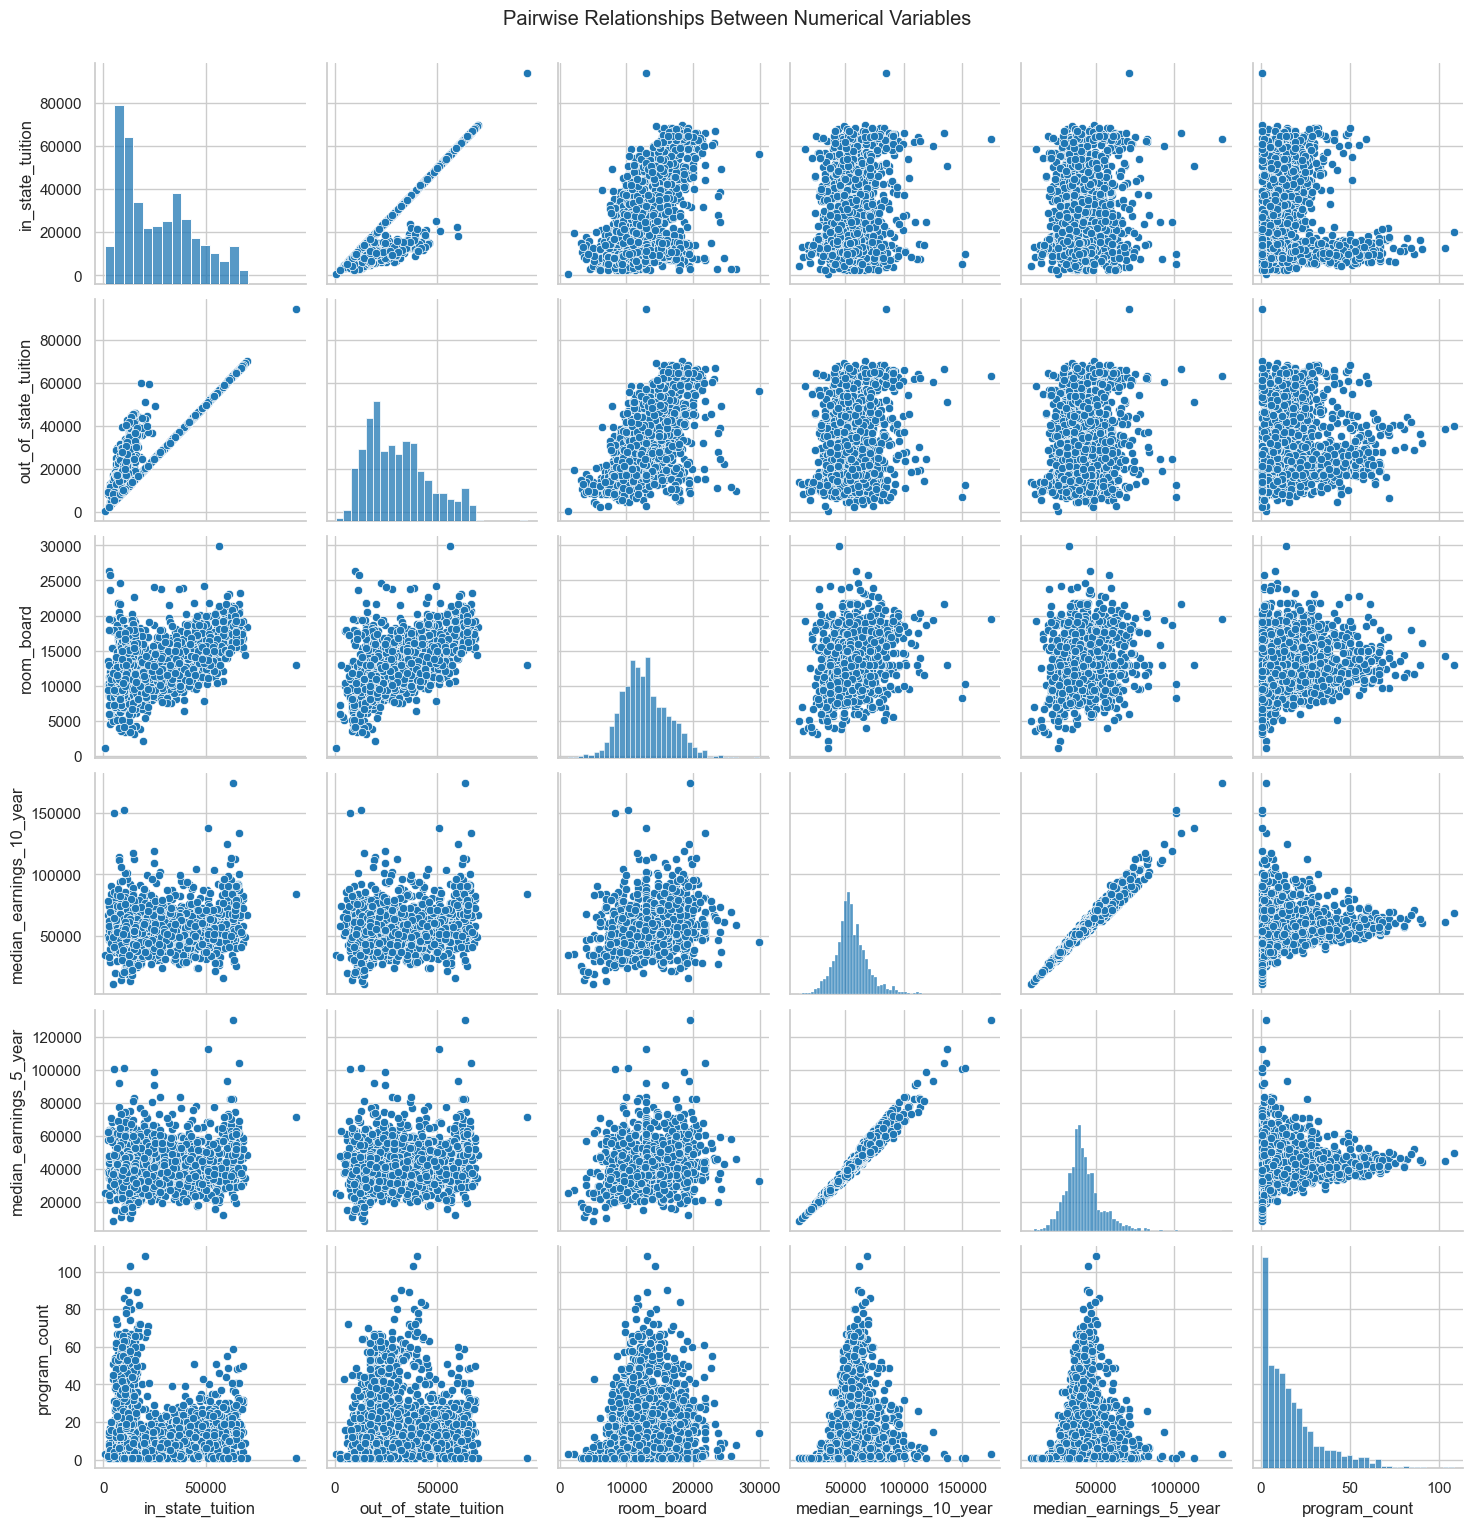

In [45]:
g = sns.pairplot(data=df[numerical_columns].dropna())
g.figure.suptitle("Pairwise Relationships Between Numerical Variables", y=1.02)
plt.show()

### Pairwise findings

- In-state and out-of-state tuition have a strong positive relationship.
- Earnings after 5 and 10 years have the clearest positive relationship in the matrix.
- Tuition and room and board show weaker positive relationships with earnings.
- Program count has weak visible relationships with most other variables.
- Several plots contain isolated points far from the main clusters, agreeing with the IQR outlier counts.

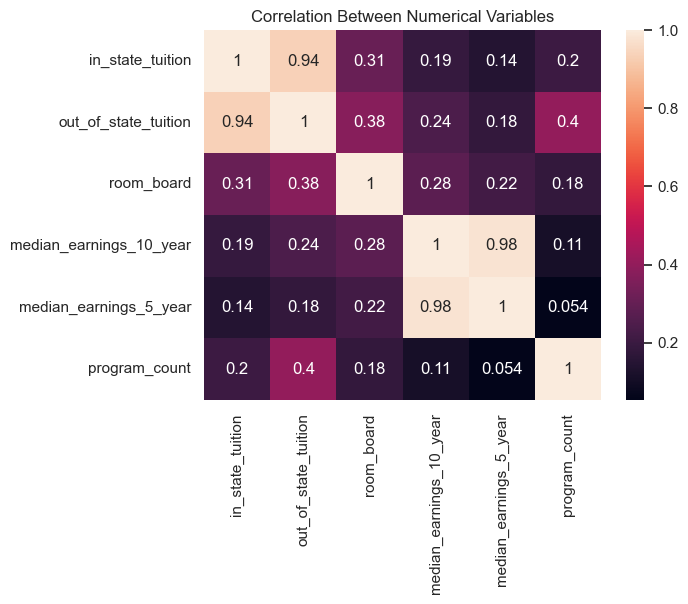

In [49]:
correlations = df[numerical_columns].corr()

g = sns.heatmap(correlations, annot=True)
g.set_title("Correlation Between Numerical Variables")
plt.xticks(rotation=90)
plt.show()

## 6. Categorical versus categorical

A cross-tabulation aggregates institution `control` against `level`. A heatmap makes the combinations easy to compare.

level              four-year  two-year
control                               
private-forprofit        236       155
private-nonprofit       1332       101
public                   780       788


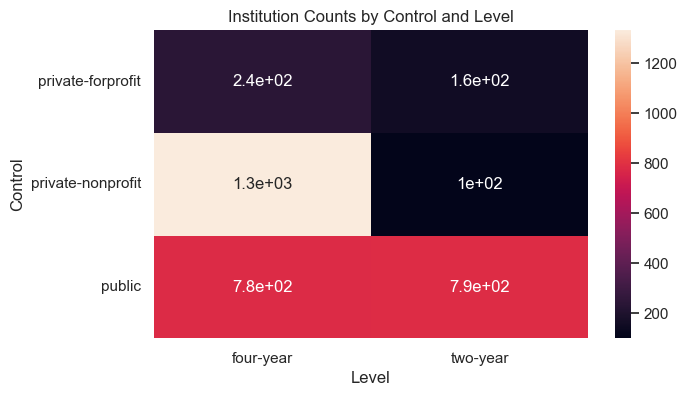

In [46]:
control_level_counts = pd.crosstab(df["control"], df["level"])
print(control_level_counts)

plt.figure(figsize=(7, 4))
g = sns.heatmap(control_level_counts, annot=True)
g.set_title("Institution Counts by Control and Level")
g.set(xlabel="Level", ylabel="Control")
plt.show()

Private nonprofit institutions are overwhelmingly four-year schools: 1,332 four-year compared with 101 two-year. Public institutions are almost evenly divided between 780 four-year and 788 two-year schools. Private for-profit institutions include 236 four-year and 155 two-year schools.

## 7. Categorical versus numerical

Color can represent a category while two numerical variables define position. The four scatter plots compare both in-state and out-of-state tuition with both 5-year and 10-year earnings. Each institution is colored by control type.

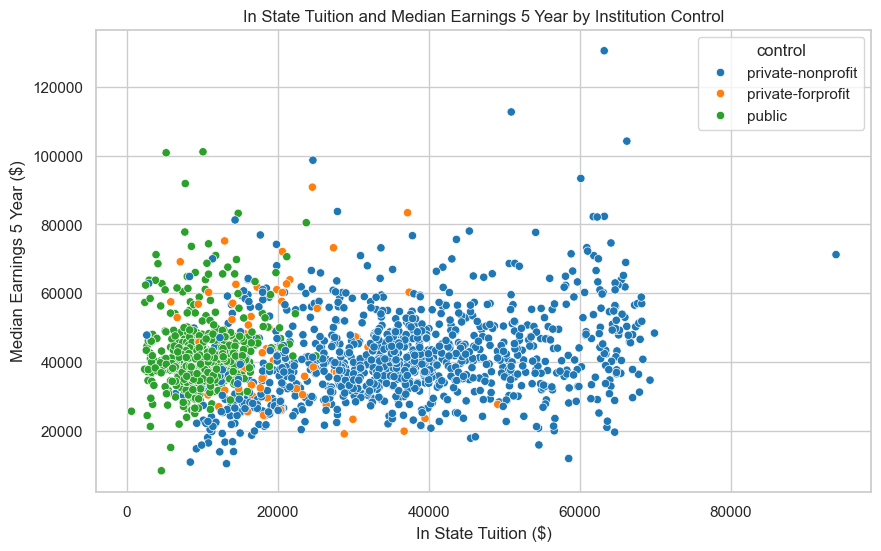

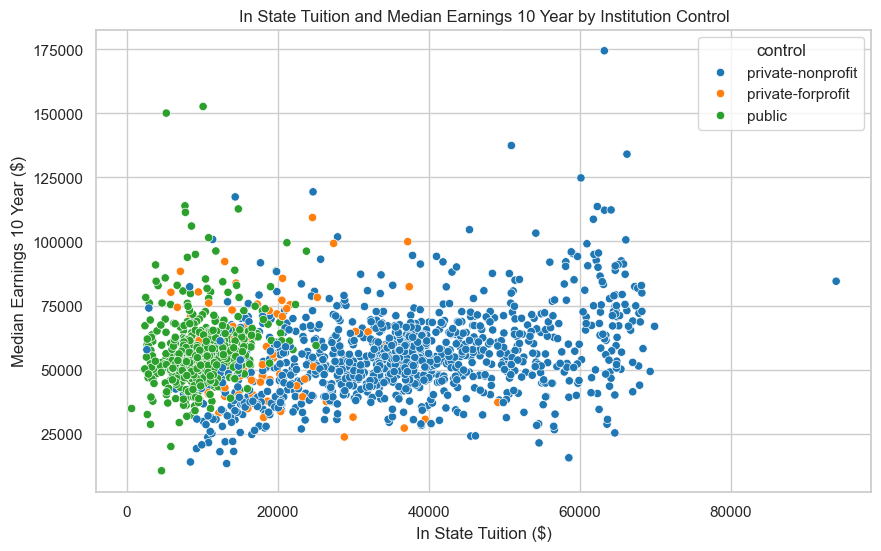

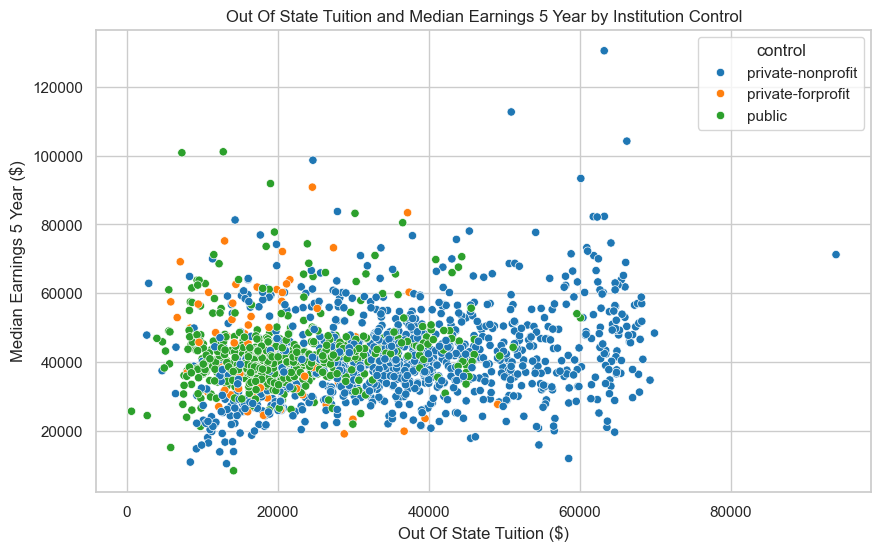

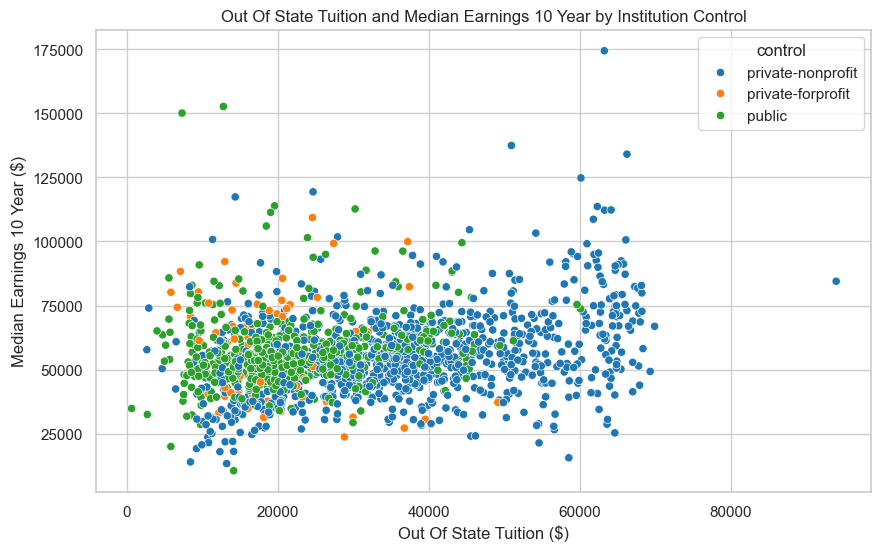

In [47]:
tuition_earnings_pairs = [
    ('in_state_tuition', 'median_earnings_5_year'),
    ('in_state_tuition', 'median_earnings_10_year'),
    ('out_of_state_tuition', 'median_earnings_5_year'),
    ('out_of_state_tuition', 'median_earnings_10_year'),
]

for tuition_column, earnings_column in tuition_earnings_pairs:
    tuition_label = tuition_column.replace('_', ' ').title()
    earnings_label = earnings_column.replace('_', ' ').title()
    plt.figure(figsize=(10, 6))
    g = sns.scatterplot(
        data=df,
        x=tuition_column,
        y=earnings_column,
        hue='control',
    )
    g.set_title(f'{tuition_label} and {earnings_label} by Institution Control')
    g.set(xlabel=f'{tuition_label} ($)', ylabel=f'{earnings_label} ($)')
    plt.show()

Across all four plots, public institutions cluster at lower tuition values, while private nonprofit institutions generally have higher tuition. The control groups overlap substantially in both 5-year and 10-year earnings, so control type and tuition alone do not separate earnings into distinct groups. The 10-year earnings values are generally higher than the 5-year values, and each comparison contains a few unusually high tuition or earnings observations.